# **Task 1: Basic K-Means Clustering**

## **Description:**

In this task, you will generate a synthetic dataset and apply the K-Means clustering algorithm to group data points into a specified number of clusters. This will help you understand how K-Means works by identifying central points (centroids) and assigning data points to the nearest centroid.

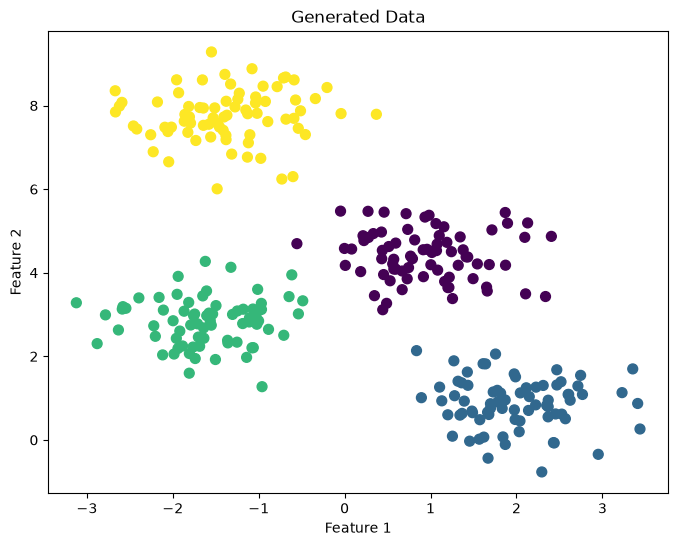

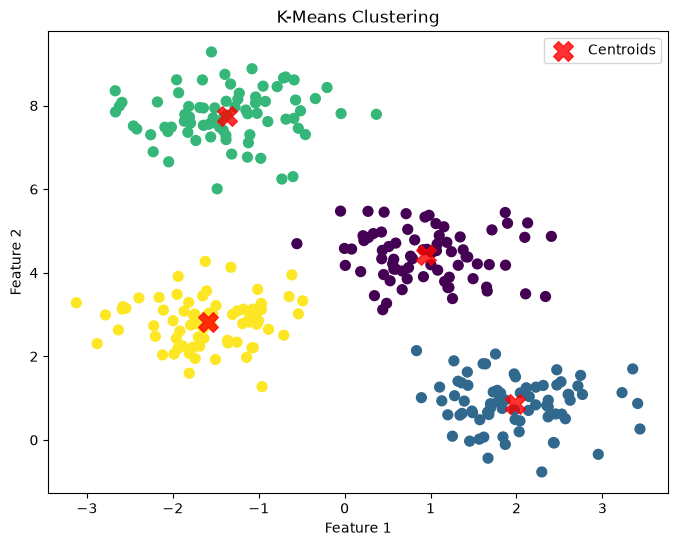

In [4]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate synthetic data
X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

# 2. Visualize the generated data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50, c=y, cmap='viridis')
plt.title("Generated Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 3. Apply K-Means clustering
k_means = KMeans(n_clusters=4, init='k-means++', max_iter=300, random_state=0, n_init=10)
y_kmeans = k_means.fit_predict(X)

# 4. Visualize the clusters
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

# 5. Plot the centroids
centers = k_means.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.8, marker='X', label='Centroids')

# 6. Add graph labels
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

# Task 2: Exploring the Elbow Method for Optimal K

## Description

Determining the optimal number of clusters (K) is an important step in K-Means clustering. This task uses the Elbow Method to identify a suitable value of K by plotting the Within-Cluster Sum of Squares (WCSS) against the number of clusters. The optimal K is estimated by identifying the elbow point where the decrease in WCSS begins to slow down significantly.

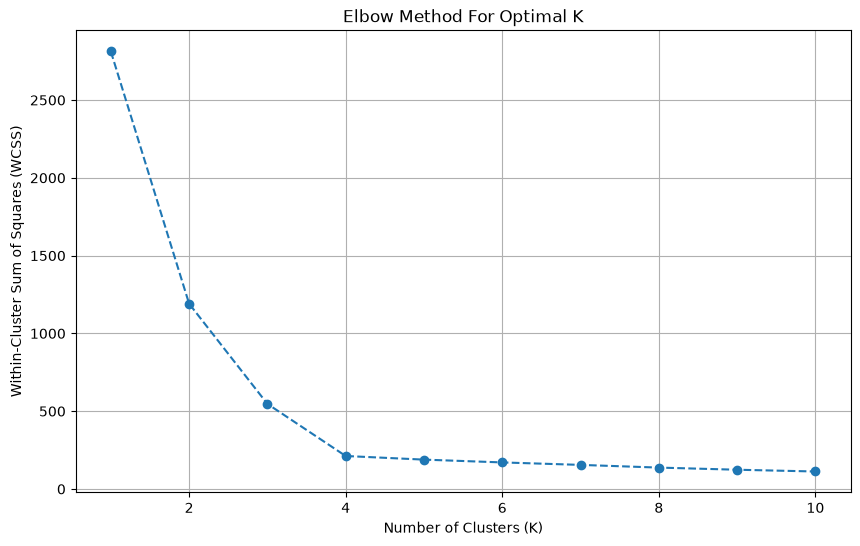

In [12]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Generate synthetic data
X, y = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=0.60,
    random_state=0
)

wcss = []
max_k = 10

# Calculate WCSS for different K values
for i in range(1, max_k + 1):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        max_iter=300,
        random_state=0,
        n_init=10
    )
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(
    range(1, max_k + 1),
    wcss,
    marker='o',
    linestyle='--'
)
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.grid(True)
plt.show()


# Task 3: Hierarchical Clustering


# Description

In this task, a synthetic dataset is generated and Hierarchical Clustering is applied to group similar data points into clusters. A dendrogram is created to visualize the hierarchical relationships between data points using Ward's linkage method. Finally, Agglomerative Clustering is used to group the data into four clusters, and the results are visualized using a scatter plot.

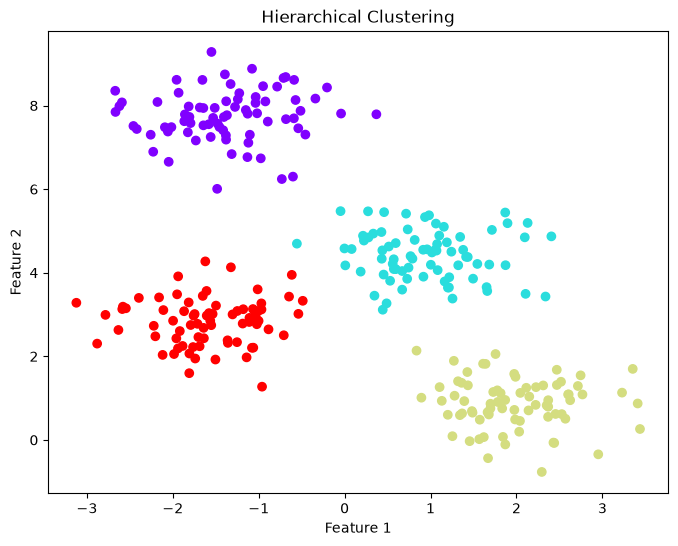

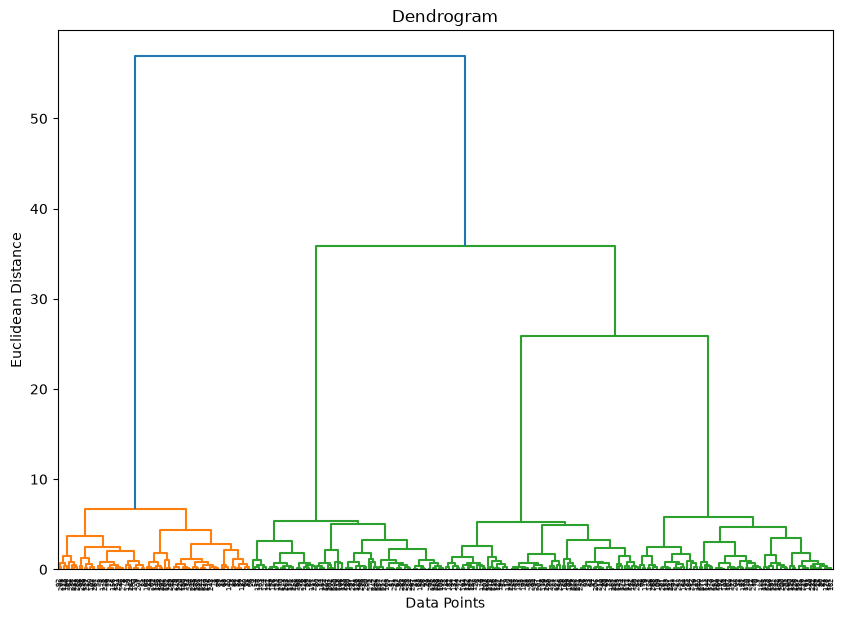

In [16]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Generate dataset
X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)



# Apply Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=4, linkage='ward')
y_hc = hc.fit_predict(X)

# Plot clusters
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_hc, cmap='rainbow')
plt.title('Hierarchical Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

# Create dendrogram
linked = linkage(X, method='ward')

plt.figure(figsize=(10, 7))
dendrogram(linked)
plt.title('Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distance')
plt.show()
